In [1]:
# Once from the project root, then select the .venv kernel.
# python -m venv .venv && source .venv/bin/activate && pip install -e .

# Portfolio Weight Optimization (PWO) Demonstration

This notebook presents the project's Portfolio Weight Optimization (PWO) pipeline for allocating capital across SPY, TLT, and GLD. 

It begins with a fixed equal-weight portfolio to show how asset returns and portfolio weights determine realized portfolio performance, and then formulates weight selection as a supervised-learning problem: 
each observation combines the market features available at a decision date, a candidate long-only weight vector whose components sum to one, and the candidate portfolio's realized cumulative return over the subsequent holding period. 

In a rolling walk-forward procedure, the model is trained only on prior observations whose forward returns are fully realized, predicts the performance of all candidate allocations, and selects the highest-scoring weight vector for the next unseen period. 

The resulting out-of-sample performance is compared with historical-mean selection and the equal-weight portfolio to assess whether conditioning asset allocations on observable market information adds value beyond simpler non-conditional alternatives.

Cells call project functions and show results in memory. They do not write `output/`. Sections 1–6 follow the scripts under `script/`. This notebook runs the full configuration and does not use the preview simplifications in those scripts. Section 2 does not standardize on all non-null rows. Section 6 runs every model in `PWO_MODEL_RUN`. Sections 7–9 follow `main_pwo.py` and `eval_pwo.py`.

In [2]:
from pathlib import Path

from util import load_yaml

PROJECT_ROOT = Path.cwd().resolve()
if PROJECT_ROOT.name == "notebook":
    PROJECT_ROOT = PROJECT_ROOT.parent

# 0. Config

Corresponds to `config.py`. This cell assigns the shared settings and the PWO settings, and omits every SPO parameter. It also loads `config/default.yaml` and `config/model.yaml`. It does not call a pipeline module. Later sections pass these names into the project functions. It passes settings forward and does not pass a data table.

Weekly sample dates provide a denser training set, while live weight selection occurs monthly and is evaluated over the following one-month holding period.


In [3]:
CONFIG_DIR = PROJECT_ROOT / "config"

TICKERS: list[str] = ["SPY", "TLT", "GLD"]  # "SPY" | "TLT" | "GLD"
START: str = "2014-12-31"
# yfinance end is exclusive. None downloads through the latest bar.
END: str | None = "2026-09-30"  # "YYYY-MM-DD" | None

CACHE_DIR: Path = PROJECT_ROOT / "data"
CACHE_FORMAT: str = "parquet"  # "parquet" | "csv"
OUTPUT_DIR: Path = PROJECT_ROOT / "output"
PRICE_COL: str = "adj_close"
PREVIEW_ROWS: int = 10

# Fit window, training-row frequency, live rebalance, and label length.
# train_window, sample_freq, rebalance_freq, label_horizon: "1y" | "6m" | "3m" | "1m" | "1w" | "1d"
WALKFORWARD: dict[str, str] = {
    "mode": "rolling",  # "rolling" | "expanding"
    "train_window": "2y",
    "sample_freq": "1w",
    "rebalance_freq": "1m",
    "label_horizon": "1m",
    "first_decision_date": "2017-01-01",  # "YYYY-MM-DD"
}

# None is equal weight across TICKERS. Evaluation uses this as the market basket.
WEIGHTS: dict[str, float] | None = None  # None | dict[str, float]

# Production path. This notebook does not write it.
PWO_SELECTIONS_CSV: Path = OUTPUT_DIR / "pwo_sel.csv"
PWO_MODEL_RUN: str | list[str] = ["hgb", "ridge", "rf"]  # "hgb" | "ridge" | "rf"
# Also build non-ML hist_mean rows in memory.
PWO_HIST_MEAN_RUN: bool = True  # True | False

# Include the equal-weight vector as a candidate.
PWO_INCLUDE_EQUAL_WEIGHT: bool = True  # True | False
# Random Dirichlet draws. The equal-weight row is extra when included.
PWO_N_WEIGHT_CANDIDATES: int = 99
# Seed for the Dirichlet draws.
PWO_WEIGHT_SEED: int = 42
# Concentration of the Dirichlet draws. A float uses the same value for every ticker.
PWO_DIRICHLET_ALPHA: float | list[float] = 1.0  # float | list[float]

# Feature windows and dataset recipe.
default_cfg = load_yaml(CONFIG_DIR / "default.yaml")
# Estimator hyperparameters.
model_cfg = load_yaml(CONFIG_DIR / "model.yaml")


# 1. Data

Corresponds to `script/run_1_data.py`. Calls `data.load_etf_panel` and `data.describe_panel`. It downloads the daily ETF panel for `TICKERS` from yfinance and displays the panel and its summary. It does not read or write cache. It passes `panel` forward.

Features, portfolio returns, and labels use adjusted closing prices. Each daily observation is treated as available after that session, so realized returns following a decision begin strictly after the decision date.


In [4]:
from data import describe_panel, load_etf_panel

In [5]:
panel = load_etf_panel(
    tickers=TICKERS,
    start=START,
    end=END,
)

In [6]:
panel

Price,timestamp,asset_id,open,high,low,close,adj_close,volume,availability_time
0,2014-12-31,GLD,114.889999,115.000000,113.279999,113.580002,113.580002,7624200,2014-12-31
1,2014-12-31,SPY,207.990005,208.190002,205.389999,205.539993,169.358124,130333800,2014-12-31
2,2014-12-31,TLT,125.699997,126.169998,125.650002,125.919998,90.924332,4993300,2014-12-31
3,2015-01-02,GLD,112.489998,114.800003,112.320000,114.080002,114.080002,7109600,2015-01-02
4,2015-01-02,SPY,206.380005,206.880005,204.179993,205.429993,169.267487,121465900,2015-01-02
...,...,...,...,...,...,...,...,...,...
8854,2026-09-28,SPY,768.349976,769.539978,763.719971,765.609985,765.609985,42694500,2026-09-28
8855,2026-09-28,TLT,78.650002,78.870003,78.269997,78.620003,78.620003,63463400,2026-09-28
8856,2026-09-29,GLD,380.940002,383.000000,379.720001,382.890015,382.890015,8122800,2026-09-29
8857,2026-09-29,SPY,766.830017,766.979980,762.349976,764.200012,764.200012,36910500,2026-09-29


In [7]:
describe_panel(panel)

,dtype,count,mean,min,25%,50%,75%,max,std
Price,,,,,,,,,
timestamp,datetime64[s],8859,2020-11-12,2014-12-31,2017-12-05,2020-11-10,2023-10-18,2026-09-29,NaN
open,float64,8859.0,227.97556,78.519997,121.190002,165.309998,287.294998,778.539978,152.833261
high,float64,8859.0,229.112368,78.519997,121.589996,166.190002,288.830002,779.369995,153.660364
low,float64,8859.0,226.740666,77.839996,120.744999,164.550003,285.579987,775.429993,151.876346
close,float64,8859.0,227.992452,78.230003,121.155003,165.350006,287.550003,777.880005,152.851963
adj_close,float64,8859.0,213.088016,73.126778,103.836758,161.848541,259.960342,775.953186,152.806635
volume,int64,8859.0,37540942.183091,1436500.0,7857000.0,15894100.0,59174100.0,507244300.0,42886872.574632
availability_time,datetime64[s],8859,2020-11-12,2014-12-31,2017-12-05,2020-11-10,2023-10-18,2026-09-29,NaN


# 2. Features

Corresponds to `script/run_pwo_2_feature.py`. Calls `feature.build_features`. It builds point-in-time features from the section 1 panel using the windows in `default_cfg`. The preview script may then standardize on all non-null rows. This notebook does not: model training standardizes each rolling train window on its own. It takes `panel` and passes `features` forward.

Features are calculated separately for each ETF. At each sample date, the dataset builder takes the latest complete vector available on or before that date and aggregates it equally across SPY, TLT, and GLD. Incomplete warm-up rows are excluded.


In [8]:
from feature import build_features

In [9]:
feature_cfg = default_cfg.get("feature", {})

features = build_features(
    panel,
    price_col=PRICE_COL,
    windows=feature_cfg.get("windows"),
)

In [10]:
features

,timestamp,asset_id,availability_time,ret_1,ret_5,ret_21,vol_21,ma_gap_21
0,2014-12-31,GLD,2014-12-31,NaN,NaN,NaN,NaN,NaN
1,2014-12-31,SPY,2014-12-31,NaN,NaN,NaN,NaN,NaN
2,2014-12-31,TLT,2014-12-31,NaN,NaN,NaN,NaN,NaN
3,2015-01-02,GLD,2015-01-02,0.004402,NaN,NaN,NaN,NaN
4,2015-01-02,SPY,2015-01-02,-0.000535,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...
8854,2026-09-28,SPY,2026-09-28,-0.007441,-0.010200,-0.004654,0.006832,0.001974
8855,2026-09-28,TLT,2026-09-28,-0.008825,-0.038875,-0.050628,0.006377,-0.031869
8856,2026-09-29,GLD,2026-09-29,0.013178,-0.042942,-0.063587,0.015394,-0.035730
8857,2026-09-29,SPY,2026-09-29,-0.001842,-0.011870,-0.004227,0.006826,0.000331


In [11]:
describe_panel(features, with_dtype=False)

,count,mean,min,25%,50%,75%,max,std
timestamp,8859,2020-11-12,2014-12-31,2017-12-05,2020-11-10,2023-10-18,2026-09-29,NaN
availability_time,8859,2020-11-12,2014-12-31,2017-12-05,2020-11-10,2023-10-18,2026-09-29,NaN
ret_1,8856.0,0.000343,-0.109424,-0.004794,0.000538,0.005642,0.105019,0.010226
ret_5,8844.0,0.001688,-0.179693,-0.010068,0.002343,0.013763,0.173582,0.021534
ret_21,8796.0,0.007024,-0.327513,-0.017868,0.007182,0.032362,0.25185,0.042807
vol_21,8796.0,0.009092,0.002155,0.006264,0.008055,0.010592,0.058565,0.004762
ma_gap_21,8799.0,0.002987,-0.205524,-0.010536,0.004019,0.017222,0.155307,0.023908


# 3. Returns

Corresponds to `script/run_pwo_3_returns.py`. Calls `portfolio.build_weighted_return_panel`. It builds daily asset returns and equal-weight contributions from the section 1 panel. This is the fixed equal-weight portfolio, not a strategy signal. It takes `panel` and displays `return_panel`. Training still builds asset returns from `panel` and applies each weight candidate, so `return_panel` is not an input to later sections.

For each asset, `contrib` equals `weight × asset_return`; summing the three contributions on the same date gives the equal-weight portfolio return.


In [12]:
from portfolio import build_weighted_return_panel

In [13]:
return_panel = build_weighted_return_panel(
    panel,
    price_col=PRICE_COL,
    tickers=TICKERS,
    weights=None,
)

In [14]:
return_panel

,timestamp,asset_id,asset_return,weight,contrib
0,2014-12-31,GLD,NaN,0.333333,NaN
1,2014-12-31,SPY,NaN,0.333333,NaN
2,2014-12-31,TLT,NaN,0.333333,NaN
3,2015-01-02,GLD,0.004402,0.333333,0.001467
4,2015-01-02,SPY,-0.000535,0.333333,-0.000178
...,...,...,...,...,...
8854,2026-09-28,SPY,-0.007441,0.333333,-0.002480
8855,2026-09-28,TLT,-0.008825,0.333333,-0.002942
8856,2026-09-29,GLD,0.013178,0.333333,0.004393
8857,2026-09-29,SPY,-0.001842,0.333333,-0.000614


In [15]:
describe_panel(return_panel, with_dtype=False)

,count,mean,min,25%,50%,75%,max,std
timestamp,8859,2020-11-12,2014-12-31,2017-12-05,2020-11-10,2023-10-18,2026-09-29,NaN
asset_return,8856.0,0.000343,-0.109424,-0.004794,0.000538,0.005642,0.105019,0.010226
weight,8859.0,0.333333,0.333333,0.333333,0.333333,0.333333,0.333333,0.0
contrib,8856.0,0.000114,-0.036475,-0.001598,0.000179,0.001881,0.035006,0.003409


# 4. Candidates

Corresponds to `script/run_pwo_4_candidate.py`. Calls `candidate.build_weight_candidates`. It builds the full long-only weight table from the section 0 settings: one equal-weight row when `PWO_INCLUDE_EQUAL_WEIGHT` is true, and `PWO_N_WEIGHT_CANDIDATES` Dirichlet draws. Each row is non-negative and sums to one. It does not use `panel`. It passes `weight_candidates` forward.

The fully invested, long-only candidates are sampled once with the configured seed and reused at every date; they are not redrawn in response to test performance. The current candidate space has no separate cash, leverage, or short allocation.


In [16]:
from candidate import build_weight_candidates

In [17]:
weight_candidates = build_weight_candidates(
    TICKERS,
    n_candidates=PWO_N_WEIGHT_CANDIDATES,
    seed=PWO_WEIGHT_SEED,
    include_equal_weight=PWO_INCLUDE_EQUAL_WEIGHT,
    dirichlet_alpha=PWO_DIRICHLET_ALPHA,
)

In [18]:
weight_candidates

,candidate_id,is_equal_weight,w_SPY,w_TLT,w_GLD
0,weight_000,True,0.333333,0.333333,0.333333
1,weight_001,False,0.337425,0.327879,0.334696
2,weight_002,False,0.153827,0.047522,0.798651
3,weight_003,False,0.305613,0.677200,0.017187
4,weight_004,False,0.474411,0.031929,0.493660
...,...,...,...,...,...
95,weight_095,False,0.649923,0.036282,0.313794
96,weight_096,False,0.600393,0.028500,0.371107
97,weight_097,False,0.016920,0.897858,0.085221
98,weight_098,False,0.068181,0.303266,0.628552


# 5. Dataset

Corresponds to `script/run_pwo_5_dataset.py`. Calls `dataset.build_pwo_training_table` and `model.run_pwo_hist_mean_selection`. It builds one training row for each sample date and each weight candidate: market features, the weight vector, and the realized cumulative return over the following hold. The preview script rebuilds features and candidates inside that call. This notebook passes `features` and `weight_candidates` through, then selects the candidate with the highest historical mean at each decision date. It takes `panel`, `features`, and `weight_candidates`, and passes `pwo_training_table` to section 6. `hist_mean_selections` is passed to section 7.

Training keeps `pwo_training_table`. A row is used only when its `decision_date` is earlier than the live decision and its `label_end` is no later than that decision, inside the rolling train window. The inputs are `ret_1`, `ret_5`, `ret_21`, `vol_21`, `ma_gap_21`, `w_SPY`, `w_TLT`, and `w_GLD`. The target is `label`. `decision_date` and `label_end` only choose those rows. `is_model_decision` marks live selection dates. `candidate_id` names the selected row, and historical-mean selection averages `label` by that id. `is_equal_weight` is stored on the selected row and is not a regressor. `train_start` and `label_n_days` are not read.

The target `label` is the candidate portfolio's cumulative return over `(decision_date, label_end]`. It is a per-candidate forward training outcome, not the annualized return or Sharpe ratio reported in the final evaluation.


In [19]:
from dataset import build_pwo_training_table
from model import run_pwo_hist_mean_selection

In [20]:
pwo_training_table = build_pwo_training_table(
    panel,
    feature_cfg=default_cfg.get("feature", {}),
    walkforward_cfg=WALKFORWARD,
    dataset_cfg=default_cfg.get("dataset", {}),
    price_col=PRICE_COL,
    tickers=TICKERS,
    n_weight_candidates=PWO_N_WEIGHT_CANDIDATES,
    weight_seed=PWO_WEIGHT_SEED,
    include_equal_weight=PWO_INCLUDE_EQUAL_WEIGHT,
    dirichlet_alpha=PWO_DIRICHLET_ALPHA,
    features=features,
    weight_candidates=weight_candidates,
    show_progress=True,
)
hist_mean_selections = run_pwo_hist_mean_selection(
    pwo_training_table,
    walkforward_cfg=WALKFORWARD,
    min_train_rows=int(model_cfg.get("min_train_rows", 3)),
    show_progress=True,
)

pwo_dataset                         :   0%|          |     0/71000 [00:00<?, ?it/s]

pwo_hist_mean                       :   0%|          |    0/ 116 [00:00<?, ?it/s]

In [21]:
pwo_training_table

,decision_date,label_end,train_start,is_model_decision,candidate_id,is_equal_weight,w_SPY,w_TLT,w_GLD,ret_1,ret_5,ret_21,vol_21,ma_gap_21,label,label_n_days
0,2015-02-05,2015-03-05,2013-02-05,False,weight_000,True,0.333333,0.333333,0.333333,0.000281,0.004064,0.028712,0.011206,0.005548,-0.028833,19
1,2015-02-05,2015-03-05,2013-02-05,False,weight_001,False,0.337425,0.327879,0.334696,0.000281,0.004064,0.028712,0.011206,0.005548,-0.028549,19
2,2015-02-05,2015-03-05,2013-02-05,False,weight_002,False,0.153827,0.047522,0.798651,0.000281,0.004064,0.028712,0.011206,0.005548,-0.043947,19
3,2015-02-05,2015-03-05,2013-02-05,False,weight_003,False,0.305613,0.677200,0.017187,0.000281,0.004064,0.028712,0.011206,0.005548,-0.029271,19
4,2015-02-05,2015-03-05,2013-02-05,False,weight_004,False,0.474411,0.031929,0.493660,0.000281,0.004064,0.028712,0.011206,0.005548,-0.019663,19
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
70495,2026-08-27,2026-09-27,2024-08-27,False,weight_095,False,0.649923,0.036282,0.313794,0.002517,0.012805,0.067781,0.009931,0.021895,-0.021630,20
70496,2026-08-27,2026-09-27,2024-08-27,False,weight_096,False,0.600393,0.028500,0.371107,0.002517,0.012805,0.067781,0.009931,0.021895,-0.025420,20
70497,2026-08-27,2026-09-27,2024-08-27,False,weight_097,False,0.016920,0.897858,0.085221,0.002517,0.012805,0.067781,0.009931,0.021895,-0.043616,20
70498,2026-08-27,2026-09-27,2024-08-27,False,weight_098,False,0.068181,0.303266,0.628552,0.002517,0.012805,0.067781,0.009931,0.021895,-0.055830,20


In [22]:
describe_panel(pwo_training_table, with_dtype=False)

,count,mean,min,25%,50%,75%,max,std
decision_date,70500,2021-01-03,2015-02-05,2018-03-29,2021-01-07,2023-11-02,2026-08-27,NaN
label_end,70500,2021-02-03,2015-03-05,2018-04-29,2021-02-07,2023-12-02,2026-09-27,NaN
train_start,70500,2019-01-04,2013-02-05,2016-03-29,2019-01-07,2021-11-02,2024-08-27,NaN
w_SPY,70500.0,0.337673,0.01406,0.127907,0.324432,0.508337,0.841557,0.218617
w_TLT,70500.0,0.307768,0.012626,0.133641,0.223629,0.45693,0.903565,0.231101
w_GLD,70500.0,0.354559,0.012683,0.14746,0.334313,0.504539,0.908756,0.227771
ret_1,70500.0,0.000232,-0.043123,-0.00332,0.00043,0.003914,0.041291,0.00652
ret_5,70500.0,0.001932,-0.082573,-0.006336,0.002701,0.010097,0.101363,0.014053
ret_21,70500.0,0.007708,-0.119777,-0.007544,0.008522,0.024964,0.116802,0.028389
vol_21,70500.0,0.00907,0.004011,0.006908,0.00836,0.010508,0.040081,0.003769


In [23]:
hist_mean_selections

,decision_date,model_id,candidate_id,is_equal_weight,w_SPY,w_TLT,w_GLD,predicted_label,realized_label,train_rows
0,2017-01-01,hist_mean,weight_025,False,0.841557,0.137798,0.020645,0.003898,0.016823,9600
1,2017-02-01,hist_mean,weight_025,False,0.841557,0.137798,0.020645,0.004420,0.046352,10100
2,2017-03-01,hist_mean,weight_066,False,0.840220,0.097395,0.062385,0.006046,-0.009675,10200
3,2017-04-01,hist_mean,weight_066,False,0.840220,0.097395,0.062385,0.006158,0.011810,10300
4,2017-05-01,hist_mean,weight_066,False,0.840220,0.097395,0.062385,0.005978,0.019824,10400
...,...,...,...,...,...,...,...,...,...,...
111,2026-04-01,hist_mean,weight_029,False,0.062300,0.028944,0.908756,0.028413,-0.024670,12100
112,2026-05-01,hist_mean,weight_029,False,0.062300,0.028944,0.908756,0.027801,-0.022372,12100
113,2026-06-01,hist_mean,weight_029,False,0.062300,0.028944,0.908756,0.026920,-0.090767,12100
114,2026-07-01,hist_mean,weight_029,False,0.062300,0.028944,0.908756,0.022786,0.001424,12100


# 6. Models

Corresponds to `script/run_pwo_6_model.py`. Calls `model.run_pwo_walkforward_selection`. On `pwo_training_table`, each model is trained only on earlier rows whose labels are fully realized, scores every weight candidate, and keeps the highest score for each decision date. The preview script uses the first model in `PWO_MODEL_RUN`. This notebook does not use that simplification: it uses the full `pwo_training_table` and every model in `PWO_MODEL_RUN`. It takes `pwo_training_table` and passes `pwo_selections` forward.

Candidates are ranked within each decision date, so relative scores determine the choice even when absolute predictions are imperfect. Standardization is fitted separately on each rolling training fold.


In [24]:
from model import run_pwo_walkforward_selection

In [25]:
pwo_selections = run_pwo_walkforward_selection(
    pwo_training_table,
    walkforward_cfg=WALKFORWARD,
    model_cfg=model_cfg,
    model_ids=PWO_MODEL_RUN,
    show_progress=True,
)

pwo_model                           :   0%|          |    0/ 348 [00:00<?, ?it/s]

In [26]:
pwo_selections

,decision_date,model_id,candidate_id,is_equal_weight,w_SPY,w_TLT,w_GLD,predicted_label,realized_label,train_rows
0,2017-01-01,hgb,weight_005,False,0.516844,0.115498,0.367659,-0.026353,0.028531,9600
1,2017-02-01,hgb,weight_019,False,0.825001,0.116353,0.058645,-0.011284,0.046645,10100
2,2017-03-01,hgb,weight_019,False,0.825001,0.116353,0.058645,-0.001037,-0.009273,10200
3,2017-04-01,hgb,weight_019,False,0.825001,0.116353,0.058645,-0.010965,0.011739,10300
4,2017-05-01,hgb,weight_019,False,0.825001,0.116353,0.058645,0.002710,0.020023,10400
...,...,...,...,...,...,...,...,...,...,...
343,2026-04-01,ridge,weight_029,False,0.062300,0.028944,0.908756,0.017946,-0.024670,12100
344,2026-05-01,ridge,weight_029,False,0.062300,0.028944,0.908756,0.032930,-0.022372,12100
345,2026-06-01,ridge,weight_029,False,0.062300,0.028944,0.908756,0.032910,-0.090767,12100
346,2026-07-01,ridge,weight_029,False,0.062300,0.028944,0.908756,0.025819,0.001424,12100


# 7. Selections

Corresponds to `main_pwo.py`. It does not reload prices, rebuild `pwo_training_table`, or fit models again. When `PWO_HIST_MEAN_RUN` is true, it stacks `pwo_selections` and `hist_mean_selections` into the selection table that `main_pwo.py` writes to `pwo_sel.csv`. This notebook does not write that file. It takes those two tables and passes `pwo_sel` forward.

`predicted_label` is available when the decision is made and determines the selected candidate; `realized_label` becomes known only after the holding period and is retained for out-of-sample evaluation.


In [27]:
import pandas as pd

In [28]:
frames = [pwo_selections, hist_mean_selections] if PWO_HIST_MEAN_RUN else [pwo_selections]
pwo_sel = pd.concat(frames, ignore_index=True).sort_values(
    ["model_id", "decision_date"]
).reset_index(drop=True)

In [29]:
pwo_sel

,decision_date,model_id,candidate_id,is_equal_weight,w_SPY,w_TLT,w_GLD,predicted_label,realized_label,train_rows
0,2017-01-01,hgb,weight_005,False,0.516844,0.115498,0.367659,-0.026353,0.028531,9600
1,2017-02-01,hgb,weight_019,False,0.825001,0.116353,0.058645,-0.011284,0.046645,10100
2,2017-03-01,hgb,weight_019,False,0.825001,0.116353,0.058645,-0.001037,-0.009273,10200
3,2017-04-01,hgb,weight_019,False,0.825001,0.116353,0.058645,-0.010965,0.011739,10300
4,2017-05-01,hgb,weight_019,False,0.825001,0.116353,0.058645,0.002710,0.020023,10400
...,...,...,...,...,...,...,...,...,...,...
459,2026-04-01,ridge,weight_029,False,0.062300,0.028944,0.908756,0.017946,-0.024670,12100
460,2026-05-01,ridge,weight_029,False,0.062300,0.028944,0.908756,0.032930,-0.022372,12100
461,2026-06-01,ridge,weight_029,False,0.062300,0.028944,0.908756,0.032910,-0.090767,12100
462,2026-07-01,ridge,weight_029,False,0.062300,0.028944,0.908756,0.025819,0.001424,12100


In [30]:
# pwo_sel.to_csv("pwo_sel.csv", index=False)

# 8. Evaluation

Corresponds to `eval_pwo.py`. Calls `evaluate.run_pwo_evaluation` and `evaluate.run_pwo_ml_vs_hist_mean_diagnosis`. Conditional and historical-mean picks use the realized labels already stored on `pwo_sel`. The equal-weight baseline and the market basket are computed from `panel`. With `WEIGHTS` left as None, those two paths match. It does not write `output/`. It takes `panel` and `pwo_sel`, and passes `pwo_summary`, `pwo_periods`, and `pwo_diagnosis` forward.

All methods use the same decision dates and holding periods. Reported returns are gross of transaction costs and slippage, which are outside the scope of this demonstration.


In [31]:
from evaluate import run_pwo_evaluation, run_pwo_ml_vs_hist_mean_diagnosis

In [32]:
pwo_summary, pwo_periods = run_pwo_evaluation(
    panel,
    selections=pwo_sel,
    walkforward_cfg=WALKFORWARD,
    price_col=PRICE_COL,
    tickers=TICKERS,
    weights=WEIGHTS,
)
pwo_diagnosis = run_pwo_ml_vs_hist_mean_diagnosis(pwo_sel)

In [33]:
pwo_summary

,sleeve,model_id,n_periods,cumulative_return,ann_return,ann_vol,sharpe,max_drawdown,hit_rate
0,baseline,,116.0,1.552598,0.101797,0.101135,1.012288,-0.208783,0.672414
1,cpo,hgb,116.0,1.111098,0.080363,0.126867,0.674520,-0.262241,0.637931
2,cpo,hist_mean,116.0,2.017503,0.121034,0.135310,0.915513,-0.234514,0.698276
3,cpo,rf,116.0,1.366668,0.093211,0.106710,0.890760,-0.222324,0.646552
4,cpo,ridge,116.0,2.033625,0.121652,0.135315,0.919603,-0.234514,0.698276
5,market,,116.0,1.552598,0.101797,0.101135,1.012288,-0.208783,0.672414


In [34]:
# pwo_summary.to_csv("pwo_summary.csv", index=False)

In [35]:
pwo_periods

,decision_date,label_end,model_id,sleeve,period_return
0,2017-01-01,2017-02-01,,baseline,0.023786
1,2017-02-01,2017-03-01,,baseline,0.030702
2,2017-03-01,2017-04-01,,baseline,-0.001573
3,2017-04-01,2017-05-01,,baseline,0.009471
4,2017-05-01,2017-06-01,,baseline,0.018858
...,...,...,...,...,...
691,2026-04-01,2026-05-01,,market,0.019649
692,2026-05-01,2026-06-01,,market,0.008585
693,2026-06-01,2026-07-01,,market,-0.036575
694,2026-07-01,2026-08-01,,market,-0.011063


In [36]:
pwo_diagnosis

,model_id,n_disagree,agree_rate,mean_realized_diff,ml_win_rate
0,hgb,116,0.000000,-0.003192,0.482759
1,rf,116,0.000000,-0.002402,0.413793
2,ridge,5,0.956897,0.001078,0.800000


# 9. Plot

Corresponds to the plot section of `eval_pwo.py`. Calls `evaluate.pwo_equity_figure`. It draws equity curves from `pwo_periods` using that script's display filters: cpo, baseline, and market, and every model. The filters change only the figure. It does not write a file. It takes `pwo_periods` and does not pass a data table forward.


In [37]:
from evaluate import pwo_equity_figure

In [38]:
SLEEVE_IDS = ["cpo", "baseline", "market"]  # "cpo" | "baseline" | "market"
MODEL_IDS = []  # "hgb" | "ridge" | "rf" | "hist_mean"
DATE_START = None  # "YYYY-MM-DD" | None
DATE_END = None  # "YYYY-MM-DD" | None

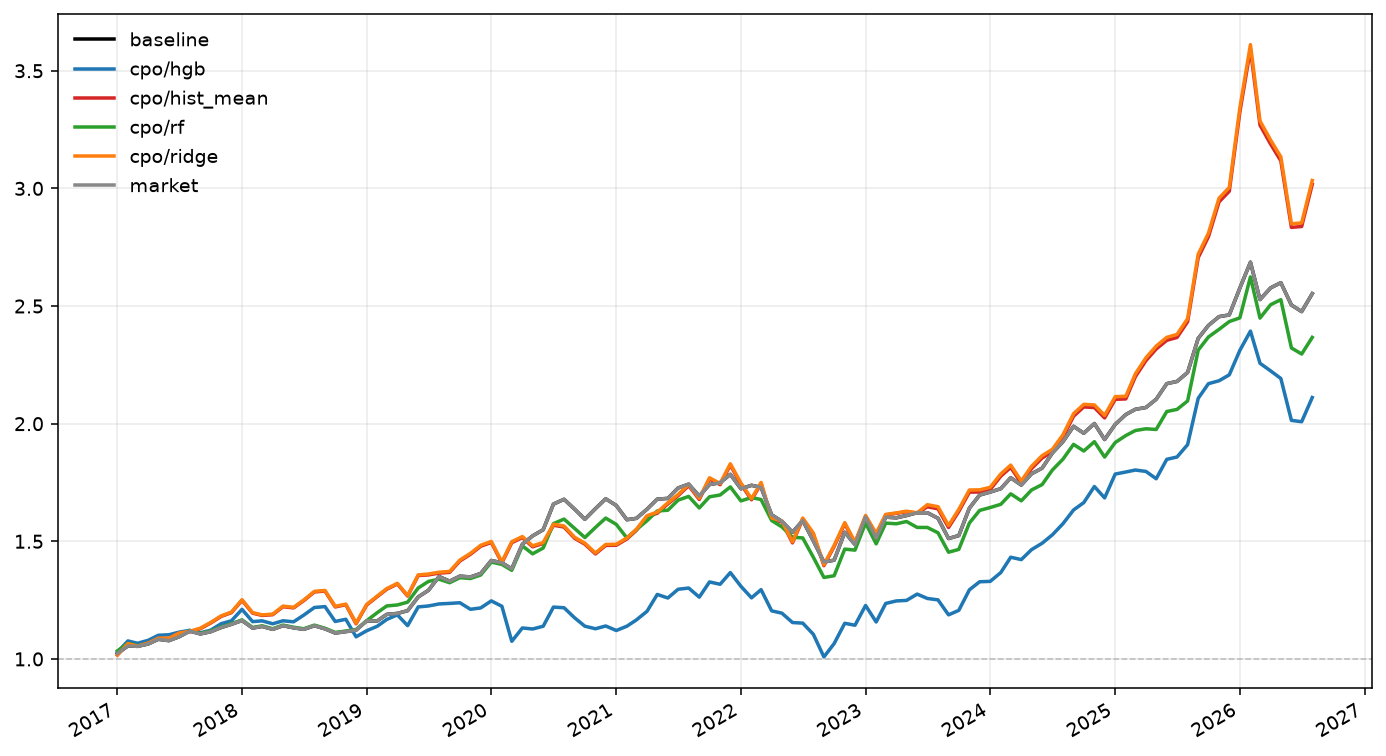

In [39]:
pwo_plot = pwo_equity_figure(
    pwo_periods,
    sleeve_ids=SLEEVE_IDS,
    model_ids=MODEL_IDS,
    date_start=DATE_START,
    date_end=DATE_END,
)

In [40]:
# pwo_plot.savefig("pwo_plot.png")